In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
from statsmodels.tools.tools import add_constant
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_curve,roc_auc_score

In [ ]:
claimants = pd.read_csv('/content/claimants.csv')
c1 = claimants.drop('CASENUM', axis=1)
print('first 5 rows\n', c1.head())
print('\ndata types:\n', c1.dtypes)
print('\nsummary\n', c1.describe())
print('missing values:\n', c1.isnull().sum())

first 5 rows
    ATTORNEY  CLMSEX  CLMINSUR  SEATBELT  CLMAGE    LOSS
0         0     0.0       1.0       0.0    50.0  34.940
1         1     1.0       0.0       0.0    18.0   0.891
2         1     0.0       1.0       0.0     5.0   0.330
3         0     0.0       1.0       1.0    31.0   0.037
4         1     0.0       1.0       0.0    30.0   0.038

data types:
 ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

summary
           ATTORNEY       CLMSEX     CLMINSUR     SEATBELT       CLMAGE  \
count  1340.000000  1328.000000  1299.000000  1292.000000  1151.000000   
mean      0.488806     0.558735     0.907621     0.017028    28.414422   
std       0.500061     0.496725     0.289671     0.129425    20.304451   
min       0.000000     0.000000     0.000000     0.000000     0.000000   
25%       0.000000     0.000000     1.000000     0.000000     9.000000   
50%       0.000000     1.000000     1.000000    

In [ ]:
'''
What Are Four Moment Business Decisions?

Mean

Variance

Skewness

Kurtosis

They describe distribution shape of numerical variables.
They are very important in Linear Regression, but their role changes in Logistic Regression.
In Linear Regression
They are critical because:
Normality assumption required (for residuals)
Homoscedasticity matters
Outliers affect coefficients strongly
So 4 moments directly influence:
Model validity
Hypothesis testing
Confidence intervals

 In Logistic Regression
Logistic regression does NOT require normality.
It assumes:
log (𝑝/1−𝑝)=𝛽0+ 𝛽1+....
So what matters more?
 Linearity in log-odds
 Multicollinearity
 Class balance
 Separation issues

'''

'\nWhat Are Four Moment Business Decisions?\n\nMean\n\nVariance\n\nSkewness\n\nKurtosis\n\nThey describe distribution shape of numerical variables.\nThey are very important in Linear Regression, but their role changes in Logistic Regression.\nIn Linear Regression\nThey are critical because:\nNormality assumption required (for residuals)\nHomoscedasticity matters\nOutliers affect coefficients strongly\nSo 4 moments directly influence:\nModel validity\nHypothesis testing\nConfidence intervals\n\n In Logistic Regression\nLogistic regression does NOT require normality.\nIt assumes:\nlog (𝑝/1−𝑝)=𝛽0+ 𝛽1+....\nSo what matters more?\n Linearity in log-odds\n Multicollinearity\n Class balance\n Separation issues\n\n'

target distribution:
 ATTORNEY
0    685
1    655
Name: count, dtype: int64


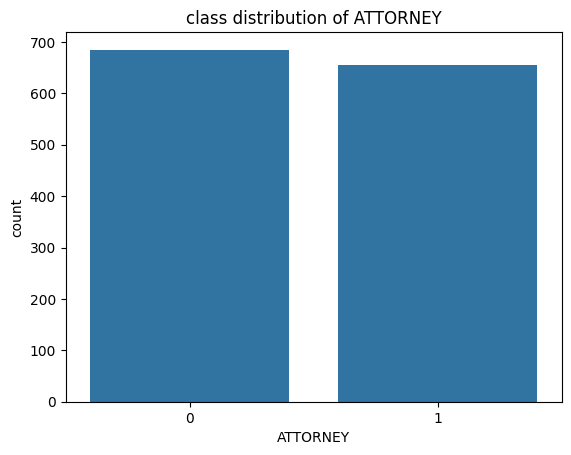

In [ ]:
print("target distribution:\n",c1['ATTORNEY'].value_counts())
sns.countplot(x='ATTORNEY',data=c1)
plt.title("class distribution of ATTORNEY")
plt.show()

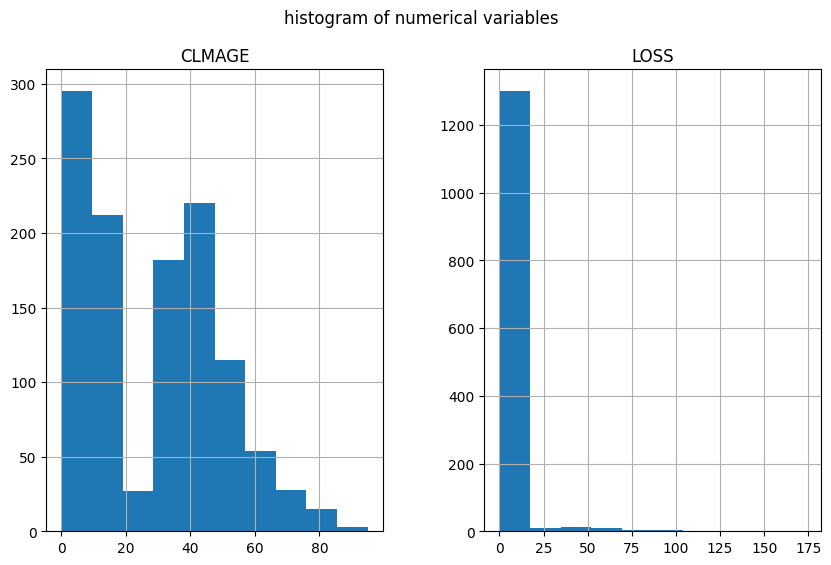

In [ ]:
c1[['CLMAGE','LOSS']].hist(figsize=(10,6))
plt.suptitle("histogram of numerical variables")
plt.show()

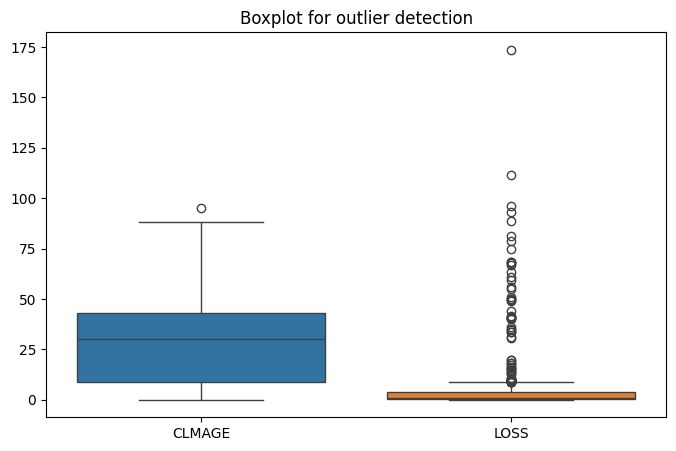

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=c1[['CLMAGE','LOSS']])
plt.title("Boxplot for outlier detection")
plt.show()

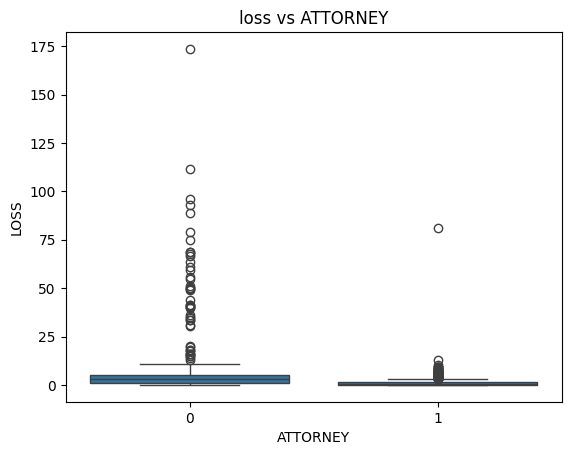

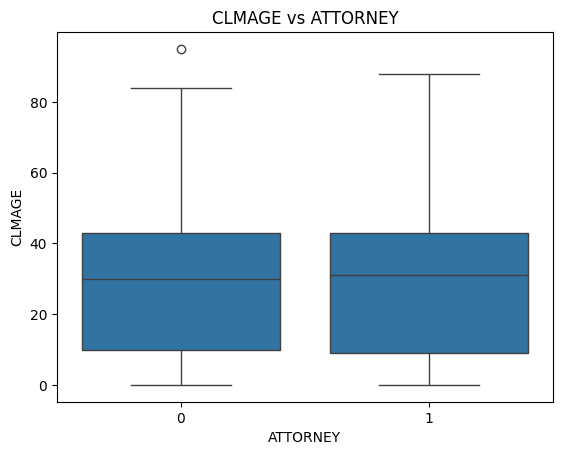

In [ ]:
#bivariate analysis
sns.boxplot(x='ATTORNEY',y='LOSS',data=c1)
plt.title("loss vs ATTORNEY")
plt.show()

sns.boxplot(x="ATTORNEY",y="CLMAGE",data=c1)
plt.title("CLMAGE vs ATTORNEY")
plt.show()

In [ ]:
print("\nCLMSEX vs ATTORNEY:\n",pd.crosstab(c1.CLMSEX,c1.ATTORNEY,normalize='index'))
print("\nCLMINSUR vs ATTORNEY:\n",pd.crosstab(c1.CLMINSUR,c1.ATTORNEY,normalize='index'))
print("\nSEATBELT vs ATTORNEY:\n",pd.crosstab(c1.SEATBELT,c1.ATTORNEY,normalize='index'))



CLMSEX vs ATTORNEY:
 ATTORNEY         0         1
CLMSEX                      
0.0       0.554608  0.445392
1.0       0.474394  0.525606

CLMINSUR vs ATTORNEY:
 ATTORNEY         0         1
CLMINSUR                    
0.0       0.633333  0.366667
1.0       0.496183  0.503817

SEATBELT vs ATTORNEY:
 ATTORNEY         0         1
SEATBELT                    
0.0       0.506299  0.493701
1.0       0.727273  0.272727


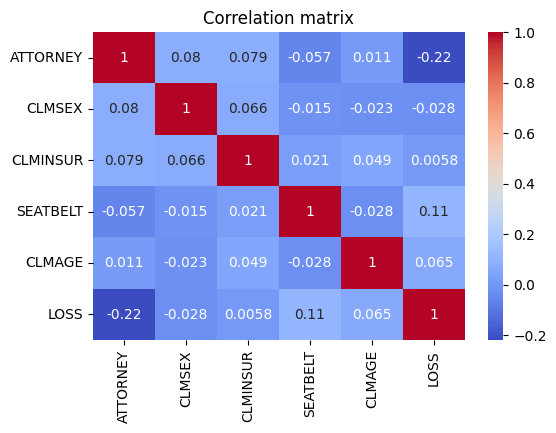

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(c1.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

In [ ]:
x=c1.drop(columns=['ATTORNEY'])
x=x.replace([np.inf,-np.inf],np.nan)
x=x.dropna()

x_const=add_constant(x)

In [ ]:
vif_Data=pd.DataFrame()
vif_Data["feature"]=x_const.columns
vif_Data["VIF"]=[variance_inflation_factor(x_const.values,i)
for i in range(x_const.shape[1])]
print("\nVariance inflation factor:\n",vif_Data)


Variance inflation factor:
     feature        VIF
0     const  13.067702
1    CLMSEX   1.004967
2  CLMINSUR   1.006637
3  SEATBELT   1.019622
4    CLMAGE   1.008392
5      LOSS   1.023449


In [ ]:
print("\nSkewness\n:",c1.skew())


Skewness
: ATTORNEY    0.044838
CLMSEX     -0.236845
CLMINSUR   -2.818710
SEATBELT    7.474911
CLMAGE      0.410035
LOSS        7.724874
dtype: float64


In [ ]:
c1['LOSS_LOG']=np.log1p(c1['LOSS'])
y=c1['ATTORNEY']
x=c1[['CLMAGE','LOSS_LOG']]

X=x.replace([np.inf,-np.inf],np.nan)
data=pd.concat([x,y],axis=1).dropna()

x_clean=add_constant(data[['CLMAGE','LOSS_LOG']])
y_clean=data['ATTORNEY']

import statsmodels.api as sm
model_temp=sm.Logit(y_clean, x_clean)

In [ ]:
#data preprocessing
!pip install feature_engine
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from feature_engine.outliers import Winsorizer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 8.5 MB/s eta 0:00:00


In [ ]:
claimants = pd.read_csv('/content/claimants.csv')
print("initial shape:",claimants.shape)
print('first 5 rows\n', c1.head())

initial shape: (1340, 7)
first 5 rows
    ATTORNEY  CLMSEX  CLMINSUR  SEATBELT  CLMAGE    LOSS  LOSS_LOG
0         0     0.0       1.0       0.0    50.0  34.940  3.581851
1         1     1.0       0.0       0.0    18.0   0.891  0.637106
2         1     0.0       1.0       0.0     5.0   0.330  0.285179
3         0     0.0       1.0       1.0    31.0   0.037  0.036332
4         1     0.0       1.0       0.0    30.0   0.038  0.037296


In [ ]:
c1=claimants.drop('CASENUM', axis=1)
c1=c1.replace(['?','NA','N/A','null','NULL',''], np.nan)
print("\ndata types:",c1.dtypes)
print("\nmissing val:",c1.isnull().sum())


data types: ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

missing val: ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64
